# 13.6. 目标检测数据集

In [17]:
%matplotlib inline
import os
import pandas as pd
import torch
import torchvision
from d2l import torch as d2l

#@save
d2l.DATA_HUB['banana-detection'] = (
    d2l.DATA_URL + 'banana-detection.zip',
    '5de26c8fce5ccdea9f91267273464dc968d20d72')


In [18]:
# 把文件移动到指定目录

In [19]:
#@save
def read_data_bananas(is_train=True):
    """读取香蕉检测数据集中的图像和标签"""
    data_dir = d2l.download_extract('banana-detection', '/home/beichen/jiaxinl/data')
    data_dir = '/home/beichen/jiaxinl/data/banana-detection'
    csv_fname = os.path.join(data_dir, 'bananas_train' 
                             if is_train else  # 
                              'bananas_val', 'label.csv')
    csv_data = pd.read_csv(csv_fname)  # 读取csv文件
    csv_data = csv_data.set_index('img_name') # 设置索引
    images, targets = [], []
    for img_name, target in csv_data.iterrows(): 
        # 逐行遍历数据 ，每次返回(index, row) 
        # index：当前行的索引。row：当前行的数据。
        images.append(torchvision.io.read_image(
            os.path.join(data_dir, 'bananas_train' if is_train else
                         'bananas_val', 'images', f'{img_name}')))
        # 这里的target包含（类别，左上角x，左上角y，右下角x，右下角y），
        # 其中所有图像都具有相同的香蕉类（索引为0）
        targets.append(list(target))
    return images, torch.tensor(targets).unsqueeze(1) / 256

- `torchvision.io.read_image()`
  - 读取图片，并直接转换为 PyTorch Tensor。\[(C,H,W)\]
- `tensor.unsqueeze(dim)`
  - 在指定位置增加一个长度为 1 的维度。
- `/256`
  - 把 Tensor 中的所有数字都除以 256。

In [20]:
#@save
class BananasDataset(torch.utils.data.Dataset):
    """一个用于加载香蕉检测数据集的自定义数据集"""
    def __init__(self, is_train):
        self.features, self.labels = read_data_bananas(is_train)
        print('read ' + str(len(self.features)) + (f' training examples' if
              is_train else f' validation examples'))

    def __getitem__(self, idx):
        return (self.features[idx].float(), self.labels[idx])

    def __len__(self):
        return len(self.features)

In [21]:
#@save
def load_data_bananas(batch_size):
    """加载香蕉检测数据集"""
    train_iter = torch.utils.data.DataLoader(BananasDataset(is_train=True),
                                             batch_size, shuffle=True)
    val_iter = torch.utils.data.DataLoader(BananasDataset(is_train=False),
                                           batch_size)
    return train_iter, val_iter

In [22]:
batch_size, edge_size = 32, 256
train_iter, _ = load_data_bananas(batch_size)
batch = next(iter(train_iter))
batch[0].shape, batch[1].shape

read 1000 training examples
read 100 validation examples


(torch.Size([32, 3, 256, 256]), torch.Size([32, 1, 5]))

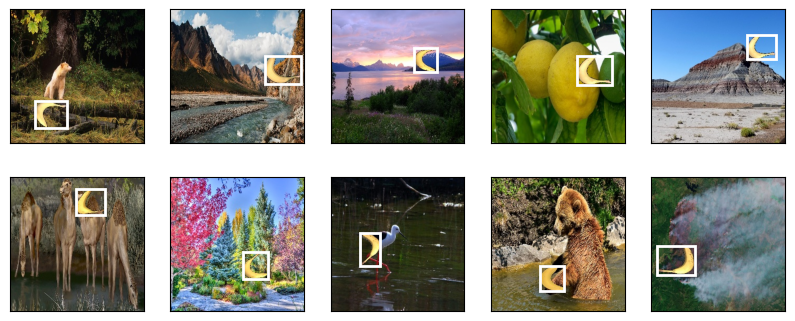

In [23]:
imgs = (batch[0][0:10].permute(0, 2, 3, 1)) / 255
axes = d2l.show_images(imgs, 2, 5, scale=2)
for ax, label in zip(axes, batch[1][0:10]):
    d2l.show_bboxes(ax, [label[0][1:5] * edge_size], colors=['w'])

- `tensor[start:end]`
  - 表示取从 start 到 end-1 的元素。

- `permute()`只是调整维度顺序，不会改变图片本身的数据，也不会改变图片的宽高。

参数	含义
imgs	要显示的图片
2	两行
5	五列
scale=2	图片显示尺寸的缩放参数

- `zip()` 的作用是：把多个可迭代对象中相同位置的元素配对。
